# Практическая работа №5. Логистическая регрессия


**Тема:** Бинарная классификация  
**Датасет:** Spotify Tracks Dataset

**Цель:** обучить модель определять популярные и непопулярные треки, а затем оценить её качество с помощью Accuracy, Precision, Recall, F1 и матрицы ошибок.

1 — Подключаем библиотеки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

2 — Загрузка данных

In [2]:
paths = [
    Path("../PR1/dataset.csv"),
    Path("PR1/dataset.csv")
]

dataset_path = next((p for p in paths if p.is_file()), None)

if dataset_path is None:
    raise FileNotFoundError("Не найден Spotify Dataset")

df = pd.read_csv(dataset_path)

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


3 — Подготовка классов

In [3]:
numeric_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms"
]

categorical_features = ["track_genre"]

data = df[numeric_features + categorical_features + ["popularity"]].copy()

data = data.dropna(subset=["popularity"])

data["is_popular"] = (data["popularity"] >= 50).astype(int)

X = data[numeric_features + categorical_features]
y = data["is_popular"]

print("Количество записей по классам:")
print(y.value_counts())

print("\nПроцент классов:")
print((y.value_counts(normalize=True) * 100).round(2))

Количество записей по классам:
is_popular
0    84633
1    29367
Name: count, dtype: int64

Процент классов:
is_popular
0    74.24
1    25.76
Name: proportion, dtype: float64


4 — Train/Test

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (91200, 11)
Test: (22800, 11)


5 — Предобработка

In [5]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

6 — Обучение модели

In [6]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Модель обучена!")
print("Первые 10 предсказаний:", y_pred[:10])

Модель обучена!
Первые 10 предсказаний: [0 0 0 1 0 0 0 0 0 0]


7 — Матрица ошибок

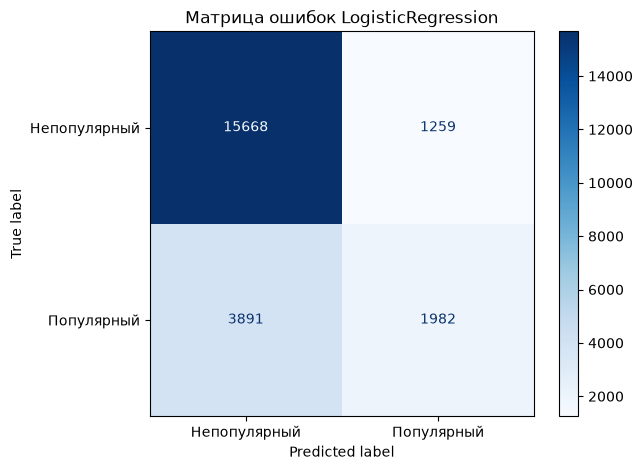

TN: 15668
FP: 1259
FN: 3891
TP: 1982


In [7]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Непопулярный", "Популярный"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Матрица ошибок LogisticRegression")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

8 — Метрики качества

In [8]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

results = pd.DataFrame({
    "Метрика": ["Accuracy", "Precision", "Recall", "F1"],
    "Значение": [accuracy, precision, recall, f1]
})

display(results.round(4))

,Метрика,Значение
0,Accuracy,0.7741
1,Precision,0.6115
2,Recall,0.3375
3,F1,0.4349


Итоги работы

Я обучил LogisticRegression определять популярные треки Spotify.

**Результаты:**

- Accuracy: [значение]
- Precision: [значение]
- Recall: [значение]
- F1: [значение]

Для этой задачи я считаю **F1 важной метрикой**, потому что она учитывает и ложные срабатывания, и пропущенные популярные треки. Если классы распределены неравномерно, одной Accuracy недостаточно.

Использовал порог **0.5**, поскольку в задании нет отдельной цены ошибок FP и FN.

**Вывод:** [написать по фактическим результатам, насколько хорошо модель определяет популярные треки].